**Objective**: This notebook introduces the initial Exploratory Data Analysis (EDA) process that was conducted, as well as the development of a baseline text classification model.

# 1. Exploratory Data Analysis

This first section will focus on the understanding of the data provided in order to get a global overview of it while also identifying potential patterns, imbalances or other factos that may influence the classification task at hand.

**Step 1:** Importing the necessary libraries and the dataset. It is important to note that only the training data will be imported since the test set will only be used for the classification of the final model and, therefore, it is not needed in this notebook.

In [215]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [216]:
train_data = pd.read_csv("data/train.csv")

In [217]:
train_data.head()

,title,tag,artist,year,views,features,lyrics,id
0,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\nDid you mean it th...,535805
1,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\n[Hook]\nEverybody wants you to...,7519483
2,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\nPeople tell me I've changed\nI find...,4892808
3,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\nDon't try to get ...,1584150
4,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...,7639050


**NOTE**: For the meaning of each feature, please refer to the *README.md* file.

**Step 2**: Understanding the structure of the dataset.

In [218]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 134967 entries, 0 to 134966
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   title     134965 non-null  str  
 1   tag       134967 non-null  str  
 2   artist    134967 non-null  str  
 3   year      134967 non-null  int64
 4   views     134967 non-null  int64
 5   features  134967 non-null  str  
 6   lyrics    134967 non-null  str  
 7   id        134967 non-null  int64
dtypes: int64(3), str(5)
memory usage: 8.2 MB


Based on the overview above, we can already identify some missing values (2) on the `title` column, with the remaining features complete (note that {} is a placeholder for missing features). This dataset has 134967 obvervations and 8 attributes, with 3 of them being numerical and the remaining 5 being string columns.

**Step 3**: Checking for duplicate `id`s.

In [219]:
train_data['id'].is_unique

True

There are no duplicates on the `id` column. Therefore, it can be set as the index of our dataframe.

In [220]:
train_data.set_index('id', inplace = True)

In [221]:
train_data

,title,tag,artist,year,views,features,lyrics
id,,,,,,,
535805,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\nDid you mean it th...
7519483,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\n[Hook]\nEverybody wants you to...
4892808,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\nPeople tell me I've changed\nI find...
1584150,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\nDon't try to get ...
7639050,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...
...,...,...,...,...,...,...,...
1702980,Manhattan,pop,Tijuana Sweetheart,2007,48,{},If I knew when I was young that I'd be older\n...
4802970,Belly Shit,rap,Lil Gotit,2019,3593,"{""Lil Troup""}",[Intro: Lil Gotit]\nCash\nWah-wah-wah\nWah-wah...
403929,The Four Loves,rock,Heath McNease,2014,301,{},[Verse 1]\nI was born inside a home\nThe young...


**Step 4**: Checking for duplicate songs on the dataset (same title, artist and lyrics).

In [222]:
bool(train_data.duplicated(subset=['title', 'artist', 'lyrics']).any())

False

**Step 5**: Analysing the target variable (`tag`).

In [223]:
tag_counts = train_data['tag'].value_counts()

display(tag_counts)
display(train_data['tag'].value_counts(normalize = True) * 100)

tag
pop        55742
rap        38584
rock       25332
rb          6203
misc        5640
country     3466
Name: count, dtype: int64

tag
pop        41.300466
rap        28.587729
rock       18.769032
rb          4.595938
misc        4.178799
country     2.568035
Name: proportion, dtype: float64

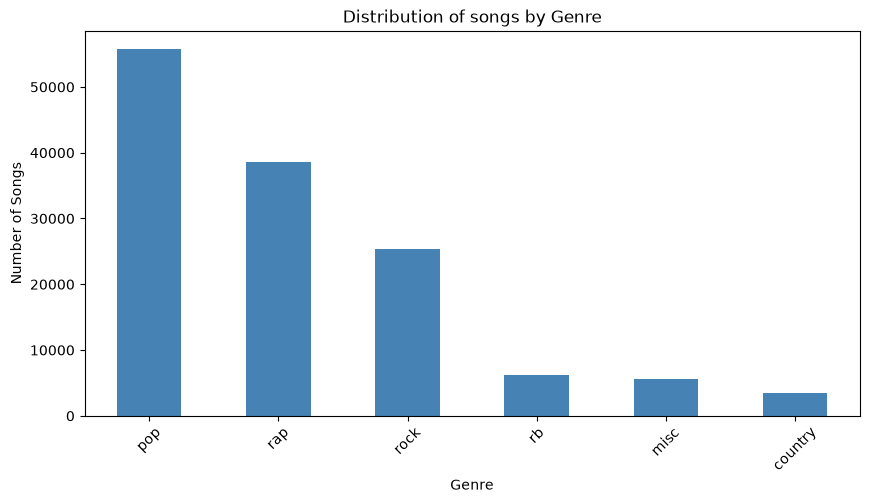

In [224]:
tag_counts.plot(kind = 'bar', figsize = (10,5), color = 'steelblue')

plt.xlabel('Genre')
plt.ylabel('Number of Songs')
plt.title('Distribution of songs by Genre')

plt.xticks(rotation = 45)
plt.show()

By analysing the ouput, we can see that the songs can be classified into **6** genres: **pop**, **rap**, **rock**, **R&B (rb)**, **miscellaneous (misc)** and **country**. The distribution of this genres across the dataset is imbalanced, with **pop** being the **most** frequent genre (41.3 %) and **country** the **least** frequent (only 2.57%). It is important to acknowledge this imbalance when dealing with a text classification task since the model might become biased towards the more representative class and fail to classify correctly the minority class. Therefore, the model evaluation process should consider metrics like the macro F1-score, instead of simply using the accuracy, to correctly assess performance across all genres.

**Step 6**: Analyse the numerical features.

In [225]:
train_data.describe()

,year,views
count,134967.000000,1.349670e+05
mean,2009.467537,3.413344e+03
std,46.287743,4.192449e+04
min,1.000000,0.000000e+00
25%,2008.000000,2.200000e+01
50%,2015.000000,8.900000e+01
75%,2019.000000,4.730000e+02
max,2024.000000,3.604497e+06


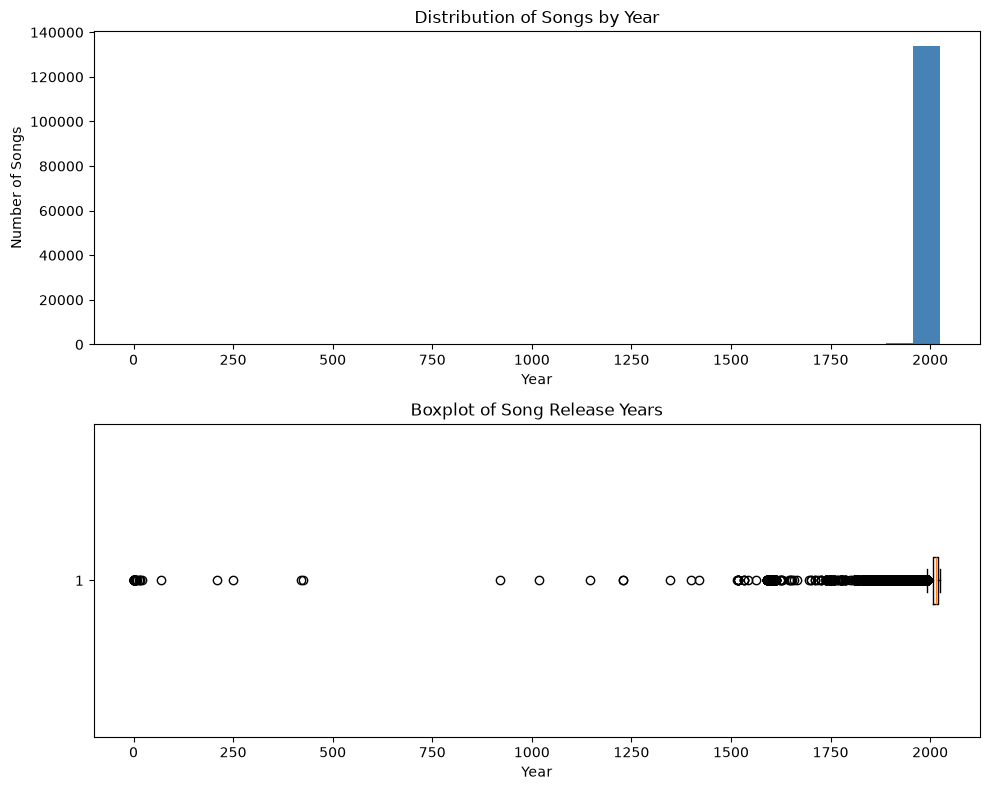

In [226]:
fig, axes = plt.subplots(2, 1, figsize = (10,8))

axes[0].hist(train_data['year'], bins = 30, color = 'steelblue')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Songs')
axes[0].set_title('Distribution of Songs by Year')

axes[1].boxplot(train_data['year'], vert = False)
axes[1].set_xlabel('Year')
axes[1].set_title('Boxplot of Song Release Years')

plt.tight_layout()
plt.show()

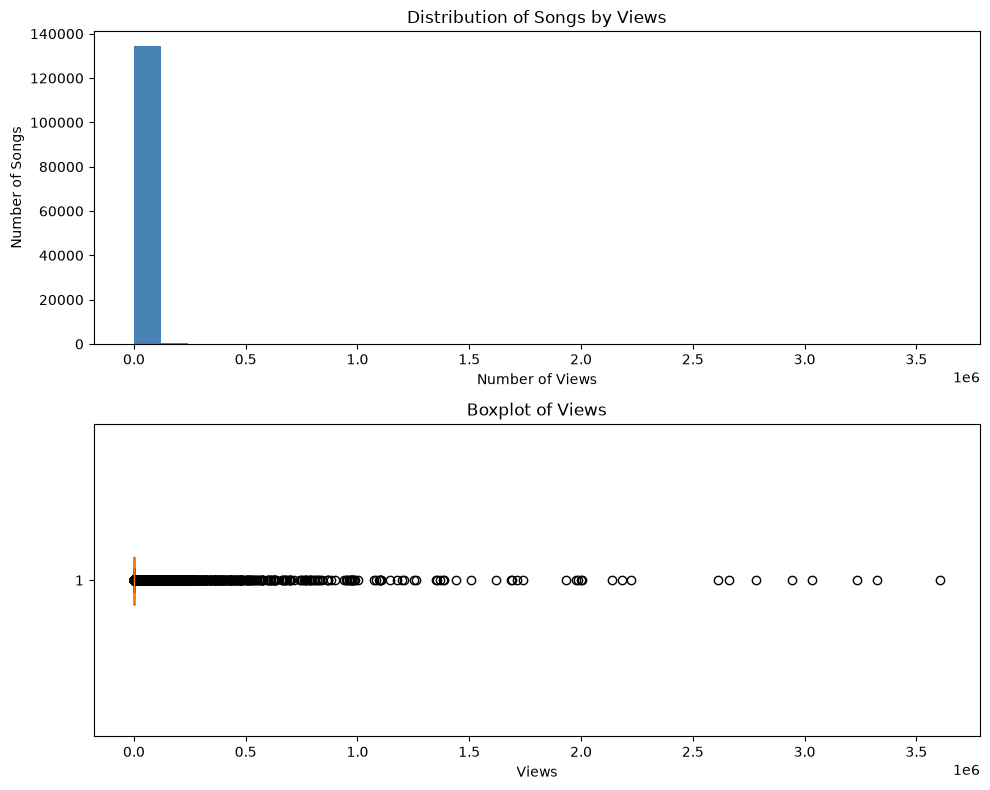

In [227]:
fig, axes = plt.subplots(2, 1, figsize = (10,8))

axes[0].hist(train_data['views'], bins = 30, color = 'steelblue')
axes[0].set_xlabel('Number of Views')
axes[0].set_ylabel('Number of Songs')
axes[0].set_title('Distribution of Songs by Views')

axes[1].boxplot(train_data['views'], vert = False)
axes[1].set_xlabel('Views')
axes[1].set_title('Boxplot of Views')

plt.tight_layout()
plt.show()

As we can see, the variable `views` is highly right-skewed (with some outliers on the right), with most songs having a low view count and few of them having a higher count (representing "hits" and high-performing tracks). To normalize this variance and to better understand the underlying pattern, we will apply a logarithmic transformation to observe the plot again.

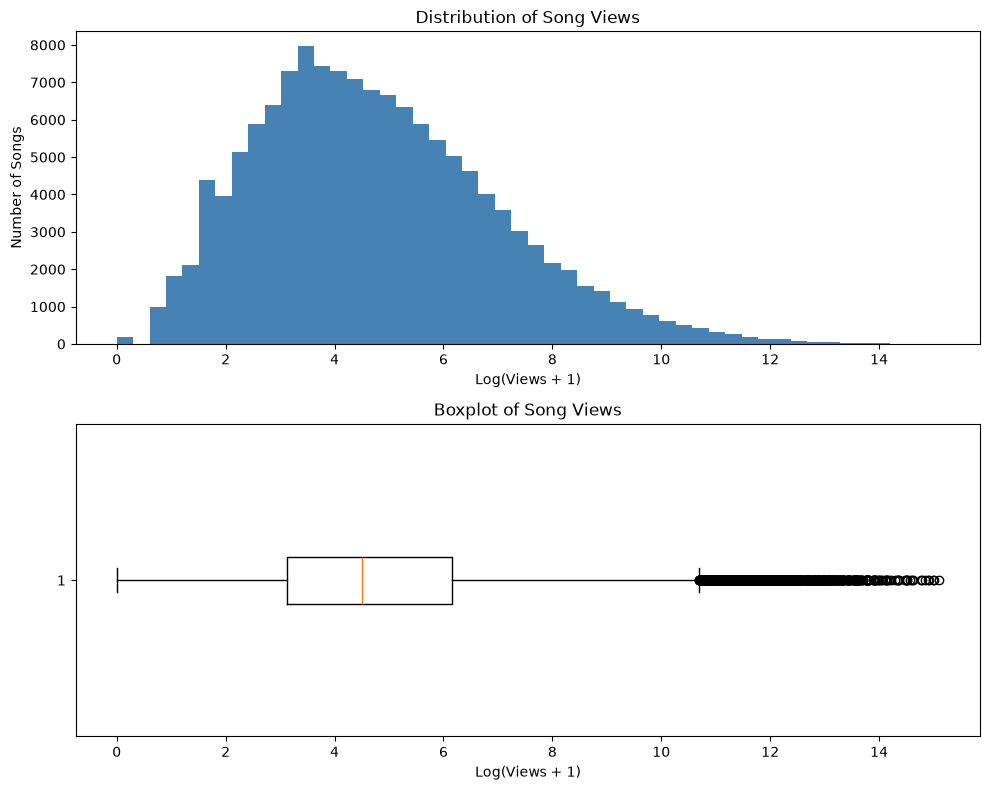

In [228]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# log1p instead of log bc there are songs with 0 views
axes[0].hist(np.log1p(train_data['views']), bins=50, color='steelblue') 
axes[0].set_title('Distribution of Song Views')
axes[0].set_xlabel('Log(Views + 1)')
axes[0].set_ylabel('Number of Songs')


axes[1].boxplot(np.log1p(train_data['views']), vert = False)
axes[1].set_title('Boxplot of Song Views')
axes[1].set_xlabel('Log(Views + 1)')

plt.tight_layout()
plt.show()

By analysing the plot above, we can see that the histogram now presents a unimodal distribution, with the main peak centered near 4 (which corresponds to nearly 54 views). It is also possible to conclude that the 50% of the songs have log(views + 1) between 3 and 6 (corresponding to between 19 and 402 views).

**Step 7**: Removing the `year` column.

**NOTE**: For the purpose of this project, this variable will not be needed since the **Genre Identification** will be done purely by analysing the lyrics and the **Sentiment Analysis** section will not involve any information regarding the release years of the songs.

In [229]:
train_data = train_data.drop(columns = ['year'])

**Step 8**: Analysing the categorical variables.

In [230]:
train_data.describe(include='O')

,title,tag,artist,features,lyrics
count,134965,134967,134967,134967,134967
unique,107703,6,74916,18389,134789
top,Intro,pop,Genius English Translations,{},Tell us that you would like to have the lyrics...
freq,135,55742,555,111928,8


In [231]:
train_data['lyric_length'] = train_data['lyrics'].str.split().str.len()

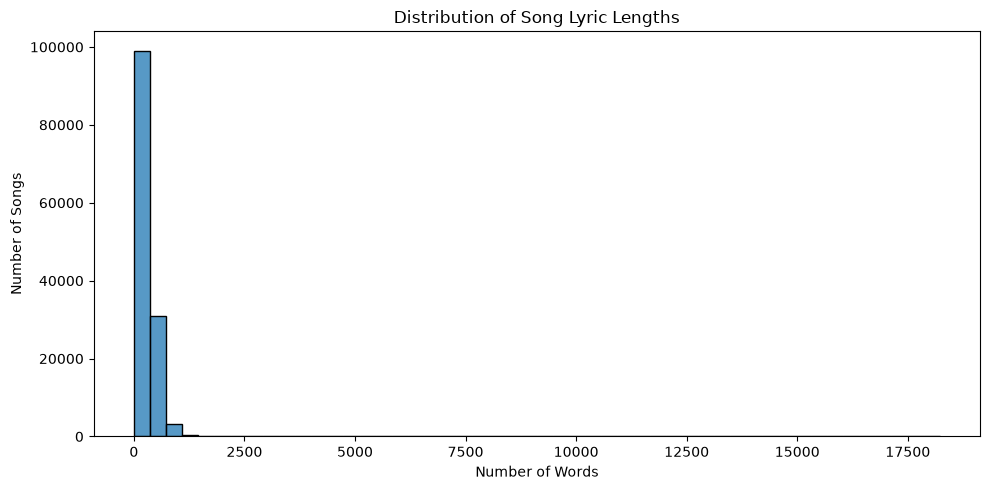

In [232]:
plt.figure(figsize = (10, 5))

sns.histplot(train_data, x = 'lyric_length', bins = 50)

plt.title('Distribution of Song Lyric Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Number of Songs')

plt.tight_layout()
plt.show()

Apart from indicating that the distribution is highly right-skewed, this plot is not much informative. Let's apply a logarithmic transformation to visualize.

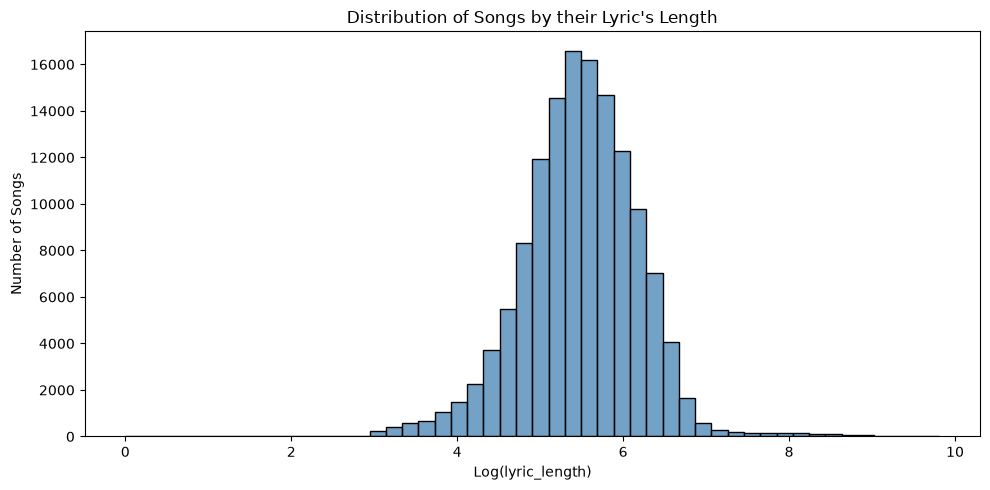

In [233]:
plt.figure(figsize=(10, 5))


sns.histplot(np.log(train_data['lyric_length']), bins=50, color='steelblue') 
plt.title("Distribution of Songs by their Lyric's Length")
plt.xlabel('Log(lyric_length)')
plt.ylabel('Number of Songs')


plt.tight_layout()
plt.show()

This distribution has a unimodal, bell-shaped curve.

In [234]:
train_data['lyric_length'].describe()

count    134967.000000
mean        317.614017
std         451.526740
min           1.000000
25%         158.000000
50%         244.000000
75%         377.000000
max       18221.000000
Name: lyric_length, dtype: float64

Most songs have between 158 to 377 word counts; however, there is also a song with a word count of 1. Let's analyse it.

In [235]:
pd.set_option('display.max_rows', None)

display(train_data['lyric_length'].value_counts().sort_index())

pd.reset_option('display.max_rows')

lyric_length
1          1
4          1
8          1
9          1
12         2
14         1
15         3
16         4
17         4
18        12
19        21
20        35
21        59
22        54
23        68
24        74
25        71
26        94
27        62
28        91
29       100
30        79
31       103
32        95
33        83
34        99
35        88
36        92
37        89
38        81
39       129
40        84
41       102
42       108
43       120
44       106
45       123
46       116
47       111
48       120
49       125
50       117
51       114
52       125
53       137
54       124
55       142
56       130
57       126
58       152
59       139
60       152
61       123
62       167
63       159
64       159
65       168
66       178
67       179
68       186
69       163
70       174
71       157
72       187
73       178
74       194
75       200
76       190
77       169
78       188
79       216
80       205
81       238
82       220
83       212
84       218

In [241]:
train_data[train_data['lyric_length'] == 1]

,title,tag,artist,views,features,lyrics,lyric_length
id,,,,,,,
384771,Alison Ritz Margaret Weisman’s “Minimum Wage ...,misc,NYRitz,2,{},http://www.theatlantic.com/business/archive/20...,1


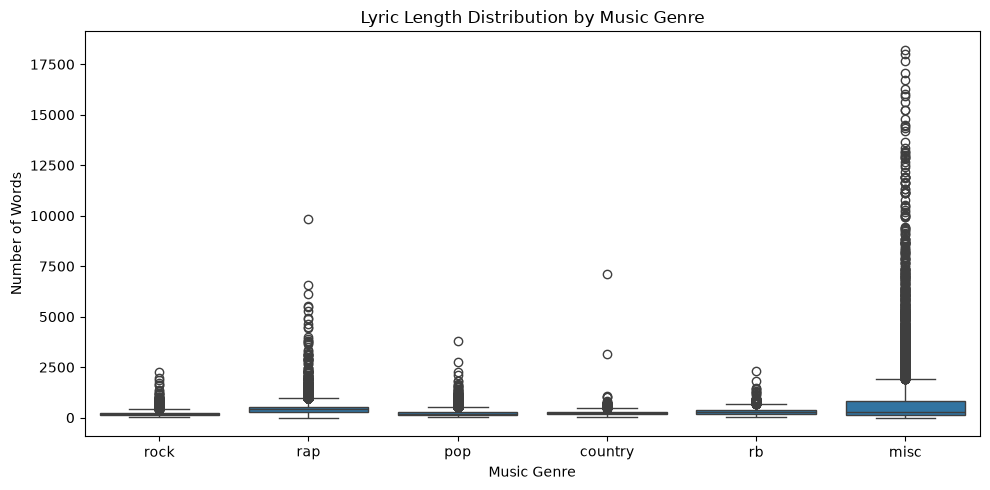

In [166]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train_data,
    x='tag',
    y='lyric_length'
)

plt.title('Lyric Length Distribution by Music Genre')
plt.xlabel('Music Genre')
plt.ylabel('Number of Words')

plt.tight_layout()
plt.show()

**Step 9**: Removing the `features` column.

**NOTE**: For the purpose of this project, this variable will not be needed since the **Genre Identification** will be done purely by analysing the lyrics and the **Sentiment Analysis** section will not involve any information regarding collaborating artists, only main ones.

In [139]:
train_data = train_data.drop(columns = ['features'])

**Step 10**: Analysing the `lyrics` variable.

As for the `lyrics` variable, the most frequent value does not contain actual song lyrics; it is actually a placeholder indicating that the actual lyrics of the song are unavailable. As such, we will treat them as missing lyrics.

In [140]:
train_data[train_data.duplicated(subset=['lyrics'], keep=False)]

,title,tag,artist,views,lyrics
id,,,,,
5993362,The Art Show Demo,rock,Significantly,7,It's my turn to make a move\nI'll smile to hid...
1561623,Free,pop,Kevin Mahogany,277,Mya you know the hook\nYou see the bait\nI kno...
2074480,The Feeling That We Have,pop,Theresa merritt,396,Put your arms around me child\nLike when you b...
1821215,This Is Why Im Hot remix instrumental feat. Ju...,pop,M.I.M.S,116,This is why I'm hot\nThis is why I'm hot\nThis...
2670235,Love Yourself,rock,The Maine,1411,[Verse 1]\nFor all the times that you rained o...
...,...,...,...,...,...
1843064,In My Arms Bimbo Jones extended mix,pop,Plumb,201,Your baby blues\nSo full of wonder\nYour curly...
2339574,Macklemore and Ryan Lewis’s “Wing$” 2,rap,TeachSkogs,7,[Verse 1]\nI was seven years old\nWhen I got m...
859758,Jubilation This Thing Called Life K.C.s Camp P...,pop,Anything Box,19,Every time I close my eyes\nI hide behind the ...


In [141]:
train_data['lyrics'].value_counts().head(1)

lyrics
Tell us that you would like to have the lyrics of this song. Then we'll make it our highest priority to find these lyrics first!\nOr perhaps you can help us out. If you have the lyrics of this song, it would be great if you can submit these. That will definitely help us and the other visitors!    8
Name: count, dtype: int64

In [142]:
placerholder_lyrics = train_data['lyrics'].value_counts().head(1).index[0] # extracting the exact text

train_data.loc[train_data['lyrics'].str.contains(placerholder_lyrics), 'lyrics'] = pd.NA

Furthermore, and since the purpose of the project is to classify songs into genres based on song lyrics, the rows which have missing lyrics will be dropped.

In [143]:
train_data = train_data.dropna(subset=['lyrics'])

In [144]:
train_data.info()

<class 'pandas.DataFrame'>
Index: 134959 entries, 535805 to 6177674
Data columns (total 5 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   title   134957 non-null  str  
 1   tag     134959 non-null  str  
 2   artist  134959 non-null  str  
 3   views   134959 non-null  int64
 4   lyrics  134959 non-null  str  
dtypes: int64(1), str(4)
memory usage: 6.2 MB


**NOTE**: Although the dataset has some missing values on the `title` variable, it does not prevent us from continuing our lyric-based analysis.